# Swapping `Transformation` `Protocol`s

The modular design of **openfe** makes it easy to swap out the alchemical `Protocol` used in a `Transformation`. This allows for easy experimentation with different protocols to see how they affect the results of a calculation. There are a few reasons why you may want to swap the protocol used in a `Transformation`. For example, you may have a failed transformation in your network leaving it in a disconnected state.
 One repair option is to retry the same ligand pair with a different protocol; another is to add new connections between ligands. For help identifying failures and adding new connections, see the [Repair a disconnected ligand network](https://docs.openfe.org/en/latest/how_to_guides/repairing_broken_networks.html) how-to guide.

In this how-to guide we will demonstrate swapping between the `RelativeHybridTopologyProtocol` and `SepTopProtocol` for a given `Transformation`.

## Swapping `RelativeHybridTopologyProtocol` to `SepTopProtocol`

This example constructs transformations using the `RelativeHybridTopologyProtocol` for the edge between `lig_ejm_31` and `lig_ejm_48` in the Tyk2 network. For your own network, you can instead provide an existing compatible complex-leg transformation, including one that failed. See the [repair a disconnected network](https://docs.openfe.org/en/latest/how_to_guides/repairing_broken_networks.html) how-to guide for more information on identifying failed transformations.

<div alert class="alert alert-info">

**Note:** SepTop performs both (complex and solvent) legs from a single `Transformation`. To swap protocols from `RelativeHybridTopologyProtocol`, provide the **complex-leg** `Transformation`, which contains all the necessary components.

</div>

/Users/joshua/mambaforge/envs/openfe_dev/lib/python3.12/site-packages/Bio/Application/__init__.py:39: BiopythonDeprecationWarning: The Bio.Application modules and modules relying on it have been deprecated.

Due to the on going maintenance burden of keeping command line application
wrappers up to date, we have decided to deprecate and eventually remove these
modules.

We instead now recommend building your command line and invoking it directly
with the subprocess module.
  warnings.warn(


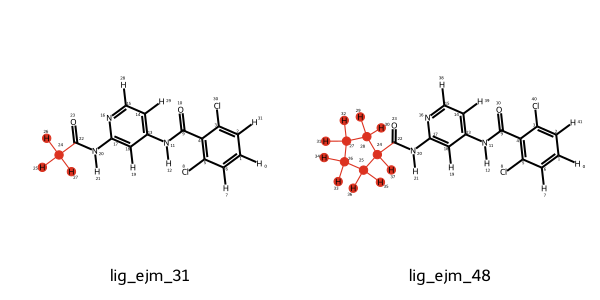

In [1]:
from gufe import (
    LigandNetwork,
    Transformation,
    ProteinComponent,
    SolventComponent,
    ChemicalSystem,
    SmallMoleculeComponent,
    SolvatedPDBComponent,
    AtomMapper,
)
import pathlib
from openfe.protocols.openmm_rfe import (
    RelativeHybridTopologyProtocol,
    RelativeHybridTopologyProtocolSettings,
)
from openfe.protocols.openmm_septop import SepTopSettings, SepTopProtocol
from openfe.setup import KartografAtomMapper

# Load our planned network from a JSON file
planned_network = LigandNetwork.from_json("assets/mst_network_tyk2.json")

# find the targeted edge from the network
edges_by_ligand_names = {
    (edge.componentA.name, edge.componentB.name): edge for edge in planned_network.edges
}
edge = edges_by_ligand_names[("lig_ejm_31", "lig_ejm_48")]
edge

We can then create the `Transformation` for this edge using the `RelativeHybridTopologyProtocol`. The `RelativeHybridTopologyProtocol` requires two transformations per edge, one for the complex and one for the solvent. We will create both transformations here.

In [2]:
# load the other components needed to create a transformation
protein = ProteinComponent.from_pdb_file("assets/tyk2_protein.pdb")
# use the default solvent component
solvent = SolventComponent()

# define the settings for the `RelativeHybridTopologyProtocol`
settings = RelativeHybridTopologyProtocol.default_settings()

# collect the transformations for this edge
hybrid_top_transformations = {}
# the `RelativeHybridTopologyProtocol` requires two transformations per edge, one for the complex and one for the solvent.
for leg in ["complex", "solvent"]:
    # make the chemical systems for the transformation states
    state_a_dict = {"ligand": edge.componentA, "solvent": solvent}
    state_b_dict = {"ligand": edge.componentB, "solvent": solvent}
    if leg == "complex":
        state_a_dict["protein"] = protein
        state_b_dict["protein"] = protein
    state_a = ChemicalSystem(state_a_dict, name=f"{leg}_{edge.componentA.name}")
    state_b = ChemicalSystem(state_b_dict, name=f"{leg}_{edge.componentB.name}")

    # adapt the settings for the `RelativeHybridTopologyProtocol` to the specific transformation states
    leg_settings = RelativeHybridTopologyProtocol._adaptive_settings(
        stateA=state_a, stateB=state_b, mapping=edge, initial_settings=settings
    )
    # make the protocol for the transformation
    protocol = RelativeHybridTopologyProtocol(settings=leg_settings)

    # make the transformation for this leg of the calculation
    hybrid_top_transformations[leg] = Transformation(
        stateA=state_a,
        stateB=state_b,
        protocol=protocol,
        mapping=edge,
        name=f"{leg}_{edge.componentA.name}_{edge.componentB.name}",
    )

The following function creates a `SepTopProtocol` transformation between the same pair of ligands. SepTop performs both the complex and solvent legs in a single `Transformation`, so the function takes the hybrid topology complex-leg transformation as input as this contains the necessary information to generate the `SepTopProtocol` transformation.

If the complex leg contains an explicitly solvated protein component, the helper adds a `SolventComponent` for the solvent leg, using the supplied component or the default. See the [user guide](https://docs.openfe.org/en/latest/guide/setup/chemical_systems_and_thermodynamic_cycles.html#) for more information on solvation models and constructing chemical systems for alchemical transformations.

<div alert class="alert alert-info">

**Note:** Some transformations may not be compatible with the `SepTopProtocol`. For example, transformations which change the net charge of the system are not yet supported. The function checks compatibility of the transformation for the `SepTopProtocol` using the protocol validation method. This does not guarantee the simulation will run successfully.

</div>

<div alert class="alert alert-warning">

**Warning:** Key settings that affect free energy results, such as the model, should be consistent across protocols. In this example, the function checks a subset of the key force field settings between the two protocols.

</div>

In [3]:
def generate_septop_transformation(
    transformation: Transformation,
    septop_settings: SepTopSettings | None = None,
    solvent_component: SolventComponent | None = None,
) -> Transformation:
    """
    Generate a new `Transformation` for the given edge using the `SepTopProtocol`.

    Parameters
    ----------
    transformation : Transformation
        The original complex leg `Transformation` using the `RelativeHybridTopologyProtocol` to be converted.
    septop_settings : SepTopSettings, optional
        The settings for the `SepTopProtocol`. If not provided, defaults are used with force field settings copied from the original transformation.
    solvent_component : SolventComponent, optional
        Used for the solvent leg of the calculation only if the complex leg contains an explicitly solvated protein component. If not provided, the default `SolventComponent` will be used.

    Notes
    -----
    The force field settings are copied from the original transformation to ensure consistency between the two protocols if septop_settings is not provided.

    Returns
    -------
    Transformation
        A new `Transformation` for the given edge using the `SepTopProtocol`.

    Raises
    ------
    ValueError
        If the provided transformation is not using the `RelativeHybridTopologyProtocol`, does not contain a complex leg or has mismatched force field selections.
    ProtocolValidationError
        If the generated `SepTopProtocol` transformation is not compatible with the provided transformation.
    """
    # check for the correct protocol type
    if not isinstance(transformation.protocol, RelativeHybridTopologyProtocol):
        raise ValueError(
            "The provided transformation is not using the RelativeHybridTopologyProtocol."
        )
    # check the complex leg has been provided
    protein_components = transformation.stateA.get_components_of_type(ProteinComponent)
    if not protein_components:
        raise ValueError(
            "The provided transformation does not contain a complex leg. A SepTopProtocol leg can only be generated from the complex leg of a RelativeHybridTopologyProtocol transformation."
        )

    # check the force field settings are consistent between the two protocols
    if septop_settings is not None:
        if (
            septop_settings.forcefield_settings.forcefields
            != transformation.protocol.settings.forcefield_settings.forcefields
        ) or (
            septop_settings.forcefield_settings.small_molecule_forcefield
            != transformation.protocol.settings.forcefield_settings.small_molecule_forcefield
        ):
            raise ValueError(
                "The force field settings for the SepTopProtocol are not consistent with the RelativeHybridTopologyProtocol. Please ensure that the same force field settings are used for both protocols."
            )

    else:
        # if no settings are provided, use the force field settings from the original transformation
        septop_settings = SepTopProtocol.default_settings()
        septop_settings.forcefield_settings = transformation.protocol.settings.forcefield_settings

    # check if we have an explicitly solvated protein component, if so we need to add a general solvent component to the transformation
    if isinstance(protein_components[0], SolvatedPDBComponent):
        if solvent_component is None:
            solvent_component = SolventComponent()

        # add the solvent component to the transformation states
        a_dict = transformation.stateA.to_dict()
        b_dict = transformation.stateB.to_dict()
        a_dict["solvent"] = solvent_component
        b_dict["solvent"] = solvent_component
        stateA = ChemicalSystem.from_dict(a_dict)
        stateB = ChemicalSystem.from_dict(b_dict)
    else:
        stateA = transformation.stateA
        stateB = transformation.stateB

    # define the settings for the `SepTopProtocol` adapting where needed
    pro_settings = SepTopProtocol._adaptive_settings(
        stateA=stateA,
        stateB=stateB,
        initial_settings=septop_settings,
    )
    # make the protocol for the transformation
    septop_protocol = SepTopProtocol(settings=pro_settings)

    # make the new transformation using the `SepTopProtocol`
    return Transformation(
        stateA=stateA,
        stateB=stateB,
        protocol=septop_protocol,
        mapping=None,
        name=f"septop_{transformation.mapping.componentA.name}_{transformation.mapping.componentB.name}",
        validate=True,  # run validation to check the edge is compatible with the SepTopProtocol - net charge changes not yet supported
    )

We can now convert a compatible `RelativeHybridTopologyProtocol` `complex` transformation to a `SepTopProtocol` transformation using the function we just defined.

In [4]:
new_septop_transformation = generate_septop_transformation(
    transformation=hybrid_top_transformations["complex"]
)
# check that the alchemical molecules are in the same end states
assert new_septop_transformation.stateA.contains(
    hybrid_top_transformations["complex"].mapping.componentA
)
assert new_septop_transformation.stateB.contains(
    hybrid_top_transformations["complex"].mapping.componentB
)
# check that the new transformation is using the SepTopProtocol
assert isinstance(new_septop_transformation.protocol, SepTopProtocol)

## Swapping `SepTopProtocol` to `RelativeHybridTopologyProtocol`

We can also convert the `SepTopProtocol` transformation back to two `RelativeHybridTopologyProtocol` transformations, one for each leg of the calculation. The `RelativeHybridTopologyProtocol` also requires an atom mapping, so we must specify how to generate one by providing a configured `AtomMapper` object.

In [5]:
def generate_hybrid_top_transformations(
    transformation: Transformation,
    atom_mapper: AtomMapper,
    hybrid_top_settings: RelativeHybridTopologyProtocolSettings | None = None,
) -> dict[str, Transformation]:
    """
    Generate new `RelativeHybridTopologyProtocol` transformations for the given edge using the provided atom mapping method.

    Parameters
    ----------
    transformation : Transformation
        The original `SepTopProtocol` transformation.
    atom_mapper : AtomMapper
        The atom mapping method to use for generating the transformations.
    hybrid_top_settings : RelativeHybridTopologyProtocolSettings, optional
        The settings for the `RelativeHybridTopologyProtocol`. If not provided, defaults are used with force field settings copied from the original transformation.

    Notes
    -----
    The force field settings are copied from the original transformation to ensure consistency between the two protocols if hybrid_top_settings is not provided.

    Returns
    -------
    dict[str, Transformation]
        A dictionary containing the new `RelativeHybridTopologyProtocol` transformations for the complex and solvent legs of the calculation.

    Raises
    ------
    ValueError
        If the provided transformation does not use the `SepTopProtocol`, does not contain one changing component in each state, or has mismatched force field selections.
    ProtocolValidationError
        If the generated `RelativeHybridTopologyProtocol` transformations are not compatible with the provided transformation.
    """
    # check for the correct protocol type
    if not isinstance(transformation.protocol, SepTopProtocol):
        raise ValueError("The provided transformation is not using the SepTopProtocol.")
    # collect the alchemical molecules for the transformation
    diff_a, diff_b = transformation.stateA.component_diff(transformation.stateB)
    if len(diff_a) != 1 or len(diff_b) != 1:
        raise ValueError(
            "The provided transformation does not contain a single alchemical molecule in each end state which is required."
        )
    # check the force field settings are consistent between the two protocols
    if hybrid_top_settings is not None:
        if (
            hybrid_top_settings.forcefield_settings.forcefields
            != transformation.protocol.settings.forcefield_settings.forcefields
        ) or (
            hybrid_top_settings.forcefield_settings.small_molecule_forcefield
            != transformation.protocol.settings.forcefield_settings.small_molecule_forcefield
        ):
            raise ValueError(
                "The force field settings for the RelativeHybridTopologyProtocol are not consistent with the SepTopProtocol. Please ensure that the same force field settings are used for both protocols."
            )
    else:
        # if no settings are provided, use the force field settings from the original transformation
        hybrid_top_settings = RelativeHybridTopologyProtocol.default_settings()
        hybrid_top_settings.forcefield_settings = transformation.protocol.settings.forcefield_settings


    # make the mapping using the provided atom mapping method
    mapping = next(iter(atom_mapper.suggest_mappings(diff_a[0], diff_b[0])))

    # extract the components needed for the calculation
    protein_component = transformation.stateA.get_components_of_type(ProteinComponent)[0]

    # cofactors are small molecule components which are not alchemical molecules
    cofactors = [
        smc
        for smc in transformation.stateA.get_components_of_type(SmallMoleculeComponent)
        if smc not in [diff_a[0], diff_b[0]]
    ]

    solvent_component = transformation.stateA.get_components_of_type(SolventComponent)[0]

    # collect the transformations for each leg
    new_transformations = {}

    # make the chemical systems for the transformation states for each leg of the calculation
    for leg in ["complex", "solvent"]:
        a_dict = {"ligand": diff_a[0]}
        b_dict = {"ligand": diff_b[0]}

        if leg == "complex":
            a_dict["protein"] = protein_component
            b_dict["protein"] = protein_component

            # add cofactors to the transformation states if they exist
            for i, cofactor in enumerate(cofactors):
                a_dict[f"cofactor_{i}"] = cofactor
                b_dict[f"cofactor_{i}"] = cofactor

        # if we have the solvent leg or a complex leg with implicit solvent add the solvent component
        if leg == "solvent" or (
            leg == "complex" and not isinstance(protein_component, SolvatedPDBComponent)
        ):
            a_dict["solvent"] = solvent_component
            b_dict["solvent"] = solvent_component

        stateA = ChemicalSystem(a_dict, name=f"{leg}_{diff_a[0].name}")
        stateB = ChemicalSystem(b_dict, name=f"{leg}_{diff_b[0].name}")

        # define the settings for the `RelativeHybridTopologyProtocol` adapting where needed
        leg_settings = RelativeHybridTopologyProtocol._adaptive_settings(
            stateA=stateA,
            stateB=stateB,
            mapping=mapping,
            initial_settings=hybrid_top_settings,
        )
        # make the protocol for the transformation
        protocol = RelativeHybridTopologyProtocol(settings=leg_settings)

        # make the transformation for this leg of the calculation
        new_transformations[leg] = Transformation(
            stateA=stateA,
            stateB=stateB,
            protocol=protocol,
            mapping=mapping,
            name=f"{leg}_{diff_a[0].name}_{diff_b[0].name}",
            validate=True,  # run validation to check the edge is compatible with the RelativeHybridTopologyProtocol
        )

    return new_transformations

We can now convert a compatible `SepTopProtocol` transformation to two `RelativeHybridTopologyProtocol` transformations using the function we just defined. Here we will use the 3D-based `KartografAtomMapper`. You can replace this with any other atom mapping method you prefer.

In [6]:
# define the default kartograf atom mapper to generate the atom mapping for the transformations
atom_mapper = KartografAtomMapper()

new_hybrid_top_transformations = generate_hybrid_top_transformations(
    transformation=new_septop_transformation, atom_mapper=atom_mapper
)

# check that the alchemical molecules are in the same end states
assert new_hybrid_top_transformations["complex"].stateA.contains(
    hybrid_top_transformations["complex"].mapping.componentA
)
assert new_hybrid_top_transformations["complex"].stateB.contains(
    hybrid_top_transformations["complex"].mapping.componentB
)
# check that the new transformations are using the RelativeHybridTopologyProtocol
assert isinstance(
    new_hybrid_top_transformations["complex"].protocol, RelativeHybridTopologyProtocol
)
assert isinstance(
    new_hybrid_top_transformations["solvent"].protocol, RelativeHybridTopologyProtocol
)

Here we check whether the regenerated mapping matches the original. A different mapper or configuration may produce a different mapping, so equality should not be assumed for other transformations.

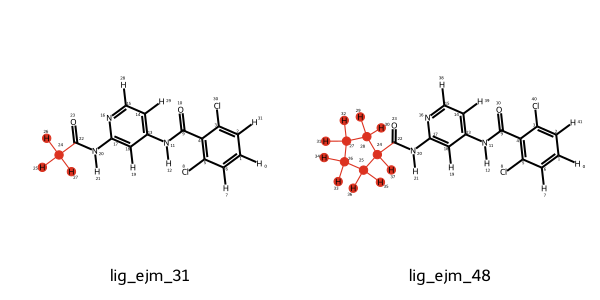

In [7]:
# check the atom mapping is the same
assert new_hybrid_top_transformations["complex"].mapping.componentA_to_componentB == hybrid_top_transformations["complex"].mapping.componentA_to_componentB
# show the new mapping
new_hybrid_top_transformations["complex"].mapping

## Next steps

[Save the replacement transformations to JSON](https://docs.openfe.org/en/latest/how_to_guides/dumping_transformation.html) and run them with [quickrun](https://docs.openfree.energy/en/latest/guide/execution/quickrun_execution.html). Once they complete successfully, combine their results with the existing campaign results.

<div alert class="alert alert-warning">

**Warning:** Gathering mixed-protocol network results is not currently supported by the CLI. Use the Python API as shown in the [mixed protocol networks tutorial](https://docs.openfe.org/en/latest/tutorials/mixed_protocol_network_tutorial.html).

</div>

## Recap

- The modular design of **openfe** allows for easy swapping of the alchemical `Protocol` used in a `Transformation`.
- This is useful for experimenting with different protocols to see how they affect the results of a calculation, as well as for repairing broken or disconnected networks. See the [repair a disconnected network](https://docs.openfe.org/en/latest/how_to_guides/repairing_broken_networks.html) how-to guide for advice on identifying failed transformations in your network.
- The protocols should be configured to use the same force field and settings should be adjusted to ensure consistency between protocols.
- Each protocol has different requirements for the `ChemicalSystem` compositions used to represent transformation end states; the helper functions defined in this notebook can be used to generate the correct `Transformation` objects for each protocol.
- `Transformations` containing any **openfe** protocol can be written to disk for execution using the [openfe quickrun CLI](https://docs.openfree.energy/en/stable/guide/introduction.html#cli-workflow).
- Analysis of a mixed-protocol network can be performed using the Python API.